# 02: Late-Delivery Prediction Model

**Goal:** at the moment of purchase, estimate the probability that an order will arrive after its estimated delivery date, so operations can act (warn the customer, prioritise the shipment).

**Rules (CLAUDE.md / ARCHITECTURE §4):** purchase-time features only · time-based split · seller history from orders *delivered* before the purchase · preprocessing fitted on training data only · seed 42 · report whichever model wins.

Code: features `src/features.py` (SQL `sql/06_ml_features.sql`) · training `src/train.py` · scoring/explanations `src/predict.py` · leakage tests `tests/test_features.py`.

## Results summary

| | Valid PR-AUC | Test PR-AUC | Test ROC-AUC | Test lift over random |
|---|---|---|---|---|
| **Logistic regression (selected)** | **0.284** | **0.094** | 0.727 | 2.13× |
| LightGBM (best of 24 configs) | 0.213 | 0.073 | 0.636 | 1.64× |
| Random ranking (= base rate) | 0.129 | 0.044 | 0.5 | 1× |

- **The simpler model wins.** Under strong drift (late rate 5.65% train → 12.88% valid → 4.42% test) LightGBM stops after a few trees and can't extrapolate; the linear model generalises better. Reported as is (rule 6).
- **The gaps are real, not luck (paired bootstrap, 1,000 resamples):** logistic regression test PR-AUC 0.094 [95% CI 0.087-0.104]; it beats LightGBM (difference CI −0.029 to −0.016) and the best one-feature rule, "farther = riskier" (test 0.059; difference CI −0.043 to −0.029).
- **Where it misses:** short-distance late orders and orders placed during platform-wide delay waves; recall ranges from 18.3% (MG) to 87.8% (PE).
- **Useful as a ranking:** the riskiest 1% / 5% of test orders are late 14.0% / 10.6% of the time, 3.2× / 2.4× the base rate.
- **Not usable as a fixed alarm:** the 5:1 cost-based threshold chosen on validation (0.045) flags 27.3% of test orders at 9.4% precision and 57.8% recall, costing 1.54× more than flagging nothing. Thresholds must be re-set as the late rate shifts.
- **Top drivers (SHAP):** promised delivery days (longer estimate = less risk), seller-customer distance (farther = more risk), customer state, same-state shipping (less risk), recent platform and seller history.
- **Saved:** `models/late_delivery_model.pkl`, `models/metadata.json`, `fact_order_risk` (96,203 scored orders, with a split column).

In [1]:
import sys
import warnings
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore", category=UserWarning)

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import shap
from sklearn.metrics import precision_recall_curve

from src.db import connect
from src.features import (
    CATEGORICAL_FEATURES,
    FEATURES,
    FORBIDDEN_COLUMNS,
    NUMERIC_FEATURES,
    load_model_table,
)
from src.predict import linear_contributions, risk_band, top_drivers
from src.train import (
    attach_train_mean,
    bootstrap_pr_auc,
    choose_threshold,
    confusion_at,
    cost_curve,
    evaluate,
    rule_baselines,
    rule_score,
    save_artifacts,
    segment_metrics,
    tune_lgbm,
    tune_logreg,
    xy,
)

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)
BLUE, ORANGE, MUTED, INK, INK2 = "#2a78d6", "#eb6834", "#c3c2b7", "#0b0b0b", "#52514e"
plt.rcParams.update(
    {
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.edgecolor": MUTED,
        "axes.labelcolor": INK2,
        "xtick.color": INK2,
        "ytick.color": INK2,
        "axes.grid": True,
        "grid.color": "#e6e5e0",
        "grid.linewidth": 0.6,
        "axes.axisbelow": True,
        "font.size": 10,
        "legend.frameon": False,
    }
)
FIG_DIR = ROOT / "docs" / "figures"
COST_FN, COST_FP = 5.0, 1.0  # assumed business costs (see section 5)

## 1. Data and the time-based split

One row per delivered order purchased 2017-01 to 2018-08. Train = 2017, validation = Jan-Mar 2018, test = Apr-Aug 2018. No shuffling: the model is always evaluated on orders placed *after* the ones it learned from.

In [2]:
table = load_model_table()
split_summary = (
    table.groupby("split", sort=False)
    .agg(
        orders=("order_id", "size"),
        late_pct=("is_late", lambda s: round(100 * s.mean(), 2)),
        first_purchase=("purchase_ts", "min"),
        last_purchase=("purchase_ts", "max"),
    )
    .loc[["train", "valid", "test"]]
)
split_summary

,orders,late_pct,first_purchase,last_purchase
split,,,,
train,43426,5.65,2017-01-05 11:56:06,2017-12-31 23:29:31
valid,20627,12.88,2018-01-01 02:48:41,2018-03-31 23:54:10
test,32150,4.42,2018-04-01 00:11:32,2018-08-29 15:00:37


**Note the drift:** validation (Jan-Mar 2018) contains the delivery spike found in the EDA, so its late rate is far above both train and test. Models are tuned on validation and evaluated on test exactly once.

## 2. Leakage guard: what the model may see

In [3]:
assert not set(FEATURES) & FORBIDDEN_COLUMNS, "a forbidden column is in the feature list"
why = {
    "promised_days": "estimate shown at checkout",
    "purchase_weekday / purchase_hour / is_nov_dec": "purchase timestamp",
    "distance_km / same_state": "customer and seller addresses",
    "order_value / freight_value / freight_ratio / n_items / n_sellers": "basket at checkout",
    "total_weight_g / total_volume_cm3 / primary_category": "product catalogue",
    "payment_type_main": "chosen at checkout (approval time is NOT used)",
    "seller_orders_90d / seller_delivered_90d / seller_late_rate_90d / seller_prior_late_rate": (
        "only orders delivered BEFORE this purchase"
    ),
    "market_late_rate_30d / market_volume_ratio": (
        "platform orders delivered / placed BEFORE this purchase"
    ),
    "customer_state / seller_state": "addresses",
}
print(
    f"{len(FEATURES)} features ({len(NUMERIC_FEATURES)} numeric, "
    f"{len(CATEGORICAL_FEATURES)} categorical)"
)
print("forbidden (never used):", sorted(FORBIDDEN_COLUMNS))
pd.DataFrame({"known at purchase because": why})

23 features (19 numeric, 4 categorical)
forbidden (never used): ['approval_hours', 'approved_ts', 'delay_days', 'delivered_carrier_ts', 'delivered_customer_ts', 'delivered_ts', 'delivery_days', 'dq_flags', 'has_comment', 'is_late', 'order_status', 'review_score']


,known at purchase because
promised_days,estimate shown at checkout
purchase_weekday / purchase_hour / is_nov_dec,purchase timestamp
distance_km / same_state,customer and seller addresses
order_value / freight_value / freight_ratio / n_items / n_sellers,basket at checkout
total_weight_g / total_volume_cm3 / primary_category,product catalogue
payment_type_main,chosen at checkout (approval time is NOT used)
seller_orders_90d / seller_delivered_90d / seller_late_rate_90d / seller_prior_late_rate,only orders delivered BEFORE this purchase
market_late_rate_30d / market_volume_ratio,platform orders delivered / placed BEFORE this...
customer_state / seller_state,addresses


## 3. Model selection on the validation set

- **Logistic regression** (median imputation + missing flags, scaling, one-hot), C and class weighting tuned.
- **LightGBM** (native categorical handling), 24 configurations, each with early stopping on validation PR-AUC.
- **Metric:** PR-AUC (average precision). With only ~4-13% late orders, accuracy is meaningless (predicting "never late" is 87-96% accurate) and ROC-AUC looks flattering. PR-AUC focuses on how well the late orders are ranked at the top. A random model scores the base rate.

In [4]:
x_tr, y_tr = xy(table, "train")
x_va, y_va = xy(table, "valid")
x_te, y_te = xy(table, "test")

logreg, logreg_grid = tune_logreg(x_tr, y_tr, x_va, y_va)
logreg_grid

,C,class_weight,valid_pr_auc
0,0.01,none,0.284021
1,0.10,none,0.275171
2,1.00,none,0.267141
3,0.01,balanced,0.267131
4,0.10,balanced,0.252280
5,1.00,balanced,0.247556


In [5]:
lgbm, lgbm_grid = tune_lgbm(x_tr, y_tr, x_va, y_va)
lgbm_grid.head(8)

,num_leaves,min_child_samples,class_weighted,best_iteration,valid_pr_auc
0,15,20,True,7,0.212975
1,15,100,True,7,0.209720
2,63,500,True,11,0.208830
3,31,100,True,11,0.206884
4,15,500,True,7,0.202464
5,63,100,True,11,0.200419
6,31,20,True,11,0.196839
7,63,20,True,14,0.196108


In [6]:
p_va = {
    "logistic regression": logreg.predict_proba(x_va)[:, 1],
    "LightGBM": lgbm.predict_proba(x_va)[:, 1],
}
valid_scores = pd.DataFrame({name: evaluate(y_va, p) for name, p in p_va.items()}).T
valid_scores["selected"] = valid_scores["pr_auc"] == valid_scores["pr_auc"].max()
valid_scores.round(4)

,pr_auc,roc_auc,base_rate,pr_auc_lift,selected
logistic regression,0.284,0.7256,0.1288,2.2049,True
LightGBM,0.213,0.6369,0.1288,1.6534,False


**Why does LightGBM lose?** Its early stopping halts after a handful of trees: patterns learned on 2017 stop helping on 2018 almost immediately. Trees also can't extrapolate. The validation period's platform late rate (`market_late_rate_30d`) is far above anything seen in training, and a tree treats every value above its largest training split the same way. The linear model extends the trend. Under this kind of drift the simpler model is more robust, so **logistic regression is selected** (rule: report whichever wins).

*Transparency note:* during development an earlier feature set (all-time seller counts instead of rolling windows) was also scored on the test period once, before drift was diagnosed. All the choices recorded here (rolling 90-day windows, market context, model choice) were made on validation PR-AUC.

### 3b. Does the model beat a simple rule?

A fair business baseline: **rank orders by a single number**, e.g. "the shorter the promised time, the riskier" or "the worse the seller's recent record, the riskier". Each rule's direction and missing-value fill are learned on **training** data; the best rule is picked on validation, the same protocol as the models.

In [7]:
rule_table, best_rule = rule_baselines(x_tr, y_tr, x_va, y_va, NUMERIC_FEATURES)
print(
    f"best single-feature rule on validation: {best_rule['feature']} "
    f"({'higher' if best_rule['direction'] > 0 else 'lower'} = riskier)"
)
rule_table.head(8).round(4)

best single-feature rule on validation: distance_km (higher = riskier)


,feature,higher_means,valid_pr_auc
0,distance_km,more risk,0.1740
1,freight_value,more risk,0.1614
2,same_state,less risk,0.1593
3,seller_late_rate_90d,more risk,0.1493
4,seller_prior_late_rate,more risk,0.1458
5,order_value,more risk,0.1403
6,total_volume_cm3,more risk,0.1344
7,total_weight_g,more risk,0.1341


**Reading it:** the best single rule is "the farther the seller from the customer, the riskier" (validation PR-AUC 0.174). Logistic regression (0.284) beats it clearly on validation. The test comparison with confidence intervals is in 4b.

## 4. Final evaluation on the test set (once)

In [8]:
model = attach_train_mean(logreg, x_tr)
p_te = {
    "logistic regression": model.predict_proba(x_te)[:, 1],
    "LightGBM": lgbm.predict_proba(x_te)[:, 1],
}
test_scores = pd.DataFrame({name: evaluate(y_te, p) for name, p in p_te.items()}).T
test_scores.round(4)

,pr_auc,roc_auc,base_rate,pr_auc_lift
logistic regression,0.0943,0.7268,0.0442,2.1343
LightGBM,0.0725,0.6355,0.0442,1.6405


### 4b. Is the difference real? Paired bootstrap confidence intervals

Resample the test orders 1,000 times (seed 42), using the **same** orders for every method in each resample, and recompute PR-AUC. If the 95% interval of a difference excludes 0, the gap is unlikely to be luck.

In [9]:
p_te_rule = rule_score(x_te, best_rule)
boot = bootstrap_pr_auc(
    y_te,
    {
        "logistic regression": p_te["logistic regression"],
        "LightGBM": p_te["LightGBM"],
        f"rule: {best_rule['feature']}": p_te_rule,
    },
)
boot.round(4)

,pr_auc,ci_low,ci_high,diff_vs_logistic regression_low,diff_vs_logistic regression_high
model,,,,,
logistic regression,0.0943,0.0873,0.1035,0.0000,0.0000
LightGBM,0.0725,0.0666,0.0791,-0.0289,-0.0159
rule: distance_km,0.0588,0.0539,0.0653,-0.0432,-0.0293


**Reading it:** logistic regression's test PR-AUC is 0.094 with a 95% interval of about 0.087-0.104. Both differences exclude 0: LightGBM is lower by 0.016-0.029 and the distance rule by 0.029-0.043. So the ranking **logistic regression > LightGBM > simple rule > random (0.044)** is not luck. The model adds value over a one-number rule, but the absolute level stays modest.

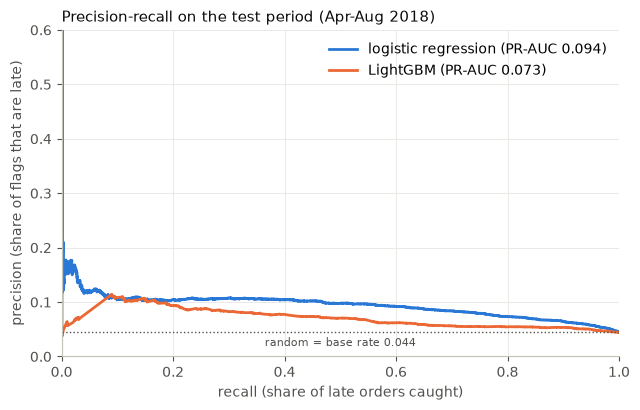

In [10]:
fig, ax = plt.subplots(figsize=(6.5, 4.2))
for (name, p), color in zip(p_te.items(), [BLUE, ORANGE], strict=True):
    prec, rec, _ = precision_recall_curve(y_te, p)
    ax.plot(
        rec,
        prec,
        color=color,
        linewidth=2,
        label=f"{name} (PR-AUC {test_scores.loc[name, 'pr_auc']:.3f})",
    )
ax.axhline(y_te.mean(), color=INK2, linewidth=1, linestyle=":")
ax.text(
    0.5,
    y_te.mean() - 0.025,
    f"random = base rate {y_te.mean():.3f}",
    ha="center",
    fontsize=8,
    color=INK2,
)
ax.set_xlabel("recall (share of late orders caught)")
ax.set_ylabel("precision (share of flags that are late)")
ax.set_xlim(0, 1)
ax.set_ylim(0, 0.6)
ax.legend(loc="upper right")
ax.set_title(
    "Precision-recall on the test period (Apr-Aug 2018)", loc="left", color=INK, fontsize=11
)
plt.tight_layout()
fig.savefig(FIG_DIR / "model_pr_curve_test.png", dpi=150)
plt.show()

In [11]:
# Ranking usefulness: precision among the k% highest-risk orders (robust to base-rate shifts)
def precision_at_top(y, p, share):
    n = max(1, int(round(share * len(p))))
    top = np.argsort(-p)[:n]
    return y[top].mean()


topk = pd.DataFrame(
    {
        f"top {int(s * 100)}%": {
            "valid precision": precision_at_top(y_va, p_va["logistic regression"], s),
            "test precision": precision_at_top(y_te, p_te["logistic regression"], s),
        }
        for s in (0.01, 0.05, 0.10, 0.20)
    }
).T
topk["test lift vs base rate"] = topk["test precision"] / y_te.mean()
topk.round(3)

,valid precision,test precision,test lift vs base rate
top 1%,0.388,0.140,3.162
top 5%,0.396,0.106,2.406
top 10%,0.357,0.105,2.386
top 20%,0.301,0.102,2.298


## 5. Choosing the decision threshold from business costs

A flag triggers an action (a proactive delay message or priority handling). Assumed costs:

- **Missed late order (false negative) = 5 units.** From Day 2: 62.4% of late orders get 1-2★, and repeat purchase is already only ~3%.
- **Unnecessary flag (false positive) = 1 unit:** the cost of the message or extra handling.

The threshold is chosen on **validation** to minimise 5·FN + 1·FP, then applied unchanged to test. Because the ratio is an assumption, the sensitivity to 3:1 and 10:1 is shown too.

In [12]:
p_va_lr = p_va["logistic regression"]
p_te_lr = p_te["logistic regression"]
chosen = choose_threshold(y_va, p_va_lr, COST_FN, COST_FP)
print({k: round(v, 4) for k, v in chosen.items()})

sens = []
for ratio in (3, 5, 10):
    th = choose_threshold(y_va, p_va_lr, ratio, 1)
    te = confusion_at(y_te, p_te_lr, th["threshold"], ratio, 1)
    sens.append(
        {
            "FN:FP cost": f"{ratio}:1",
            "threshold (from valid)": th["threshold"],
            "valid cost / flag-none": th["cost"] / th["cost_flag_none"],
            "test precision": te["precision"],
            "test recall": te["recall"],
            "test flagged %": te["flagged_pct"],
            "test cost / flag-none": te["cost"] / te["cost_flag_none"],
        }
    )
sensitivity = pd.DataFrame(sens).set_index("FN:FP cost")
sensitivity.round(3)

{'threshold': 0.045, 'cost': 9892.0, 'precision': 0.2966, 'recall': 0.4859, 'cost_flag_none': 13285.0, 'cost_flag_all': 17970.0}


,threshold (from valid),valid cost / flag-none,test precision,test recall,test flagged %,test cost / flag-none
FN:FP cost,,,,,,
3:1,0.055,0.865,0.103,0.420,17.975,1.795
5:1,0.045,0.745,0.094,0.578,27.285,1.541
10:1,0.030,0.545,0.071,0.830,51.434,1.250


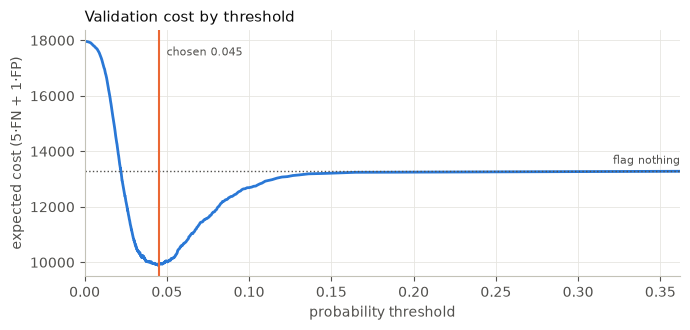

tp                  821.000
fp                 7951.000
fn                  600.000
tn                22778.000
precision             0.094
recall                0.578
flagged_pct          27.285
cost              10951.000
cost_flag_none     7105.000
cost_flag_all     30729.000
dtype: float64

In [13]:
curve = cost_curve(y_va, p_va_lr, COST_FN, COST_FP)
fig, ax = plt.subplots(figsize=(7, 3.4))
ax.plot(curve["threshold"], curve["cost"], color=BLUE, linewidth=2)
ax.axhline(chosen["cost_flag_none"], color=INK2, linestyle=":", linewidth=1)
ax.text(
    curve["threshold"].max(),
    chosen["cost_flag_none"] * 1.02,
    "flag nothing",
    ha="right",
    fontsize=8,
    color=INK2,
)
ax.axvline(chosen["threshold"], color=ORANGE, linewidth=1.5)
ax.text(
    chosen["threshold"],
    ax.get_ylim()[1] * 0.95,
    f"  chosen {chosen['threshold']:.3f}",
    fontsize=8,
    color=INK2,
)
ax.set_xlabel("probability threshold")
ax.set_ylabel(f"expected cost ({int(COST_FN)}·FN + {int(COST_FP)}·FP)")
ax.set_xlim(0, min(0.6, curve["threshold"].max()))
ax.set_title("Validation cost by threshold", loc="left", color=INK, fontsize=11)
plt.tight_layout()
fig.savefig(FIG_DIR / "model_cost_curve_valid.png", dpi=150)
plt.show()

test_cm = confusion_at(y_te, p_te_lr, chosen["threshold"], COST_FN, COST_FP)
pd.Series(test_cm).round(3)

**Reading it (honest version):** on validation the cost-based threshold beats doing nothing (cost 0.745× of flagging nothing). Applied unchanged to the calmer test period (late rate 4.42% vs 12.88%), the same threshold flags 27.3% of orders at 9.4% precision and costs **1.54× more than flagging nothing**, and the same happens at 3:1 and 10:1. At a 5:1 cost ratio a flag pays off only above 1/(1+5) ≈ 17% precision, and even the riskiest 1% of test orders reach only 14.0%. The *ranking* still works (2.1-3.2× lift over the base rate at every top-k level), but **a fixed threshold doesn't survive a three-fold drop in the late rate.** In production the threshold has to be re-set as the base rate moves (e.g. monthly on the latest labelled month), or the model used as a top-k priority list for low-cost actions.

## 6. Error analysis: where does the model miss?

Using the test period and the chosen threshold: (a) performance by purchase month, (b) by customer state, (c) how the late orders the model **missed** differ from the ones it **caught**.

In [14]:
test_rows = table[table["split"] == "test"].reset_index(drop=True)
by_month = segment_metrics(
    test_rows["purchase_ts"].dt.strftime("%Y-%m"), y_te, p_te_lr, chosen["threshold"]
)
by_month.round(3)

,orders,late,late_rate,mean_predicted,recall,precision,pr_auc
segment,,,,,,,
2018-04,6798,306,0.045,0.028,0.500,0.171,0.181
2018-05,6749,443,0.066,0.034,0.472,0.152,0.151
2018-06,6096,71,0.012,0.028,0.437,0.037,0.058
2018-07,6156,208,0.034,0.048,0.639,0.054,0.075
2018-08,6351,393,0.062,0.053,0.751,0.092,0.089


In [15]:
by_state = segment_metrics(
    test_rows["customer_state"].astype(str), y_te, p_te_lr, chosen["threshold"]
)
by_state.sort_values("late", ascending=False).head(10).round(3)

,orders,late,late_rate,mean_predicted,recall,precision,pr_auc
segment,,,,,,,
SP,14752,592,0.040,0.029,0.478,0.134,0.132
RJ,3749,163,0.043,0.053,0.791,0.072,0.099
BA,1054,114,0.108,0.065,0.798,0.120,0.118
MG,3584,109,0.030,0.025,0.183,0.058,0.060
ES,620,57,0.092,0.051,0.684,0.122,0.140
PR,1636,44,0.027,0.031,0.295,0.047,0.050
PE,522,41,0.079,0.070,0.878,0.093,0.094
RS,1600,40,0.025,0.037,0.275,0.027,0.054
CE,379,32,0.084,0.069,0.844,0.099,0.140


In [16]:
late_mask = y_te == 1
caught = late_mask & (p_te_lr >= chosen["threshold"])
missed = late_mask & (p_te_lr < chosen["threshold"])
compare_cols = [
    "promised_days",
    "distance_km",
    "same_state",
    "seller_late_rate_90d",
    "market_late_rate_30d",
    "freight_value",
    "total_weight_g",
]
missed_vs_caught = pd.DataFrame(
    {
        "caught (median)": test_rows.loc[caught, compare_cols].median(),
        "missed (median)": test_rows.loc[missed, compare_cols].median(),
        "on-time (median)": test_rows.loc[~late_mask, compare_cols].median(),
    }
)
print(
    f"late test orders: {late_mask.sum():,} | caught: {caught.sum():,} | missed: {missed.sum():,}"
)
missed_vs_caught.round(3)

late test orders: 1,421 | caught: 821 | missed: 600


,caught (median),missed (median),on-time (median)
promised_days,18.000,18.000,22.000
distance_km,667.415,318.983,396.473
same_state,0.000,0.000,0.000
seller_late_rate_90d,0.062,0.053,0.059
market_late_rate_30d,0.049,0.096,0.075
freight_value,19.440,16.390,18.380
total_weight_g,700.000,650.000,696.000


**Reading it:**

- **By month:** the model ranks best in Apr-May 2018 (PR-AUC 0.15-0.18) and worst in June, when only 1.2% of orders were late and precision at the threshold fell to 3.7%. Fewer late orders means a fixed threshold produces mostly false alarms, the same base-rate problem as in section 5.
- **By state:** it catches most late orders in the North-East (e.g. PE 87.8%, CE 84.4%, BA 79.8%) but few in MG (18.3%), RS (27.5%) and PR (29.5%), where late orders are rarer and look like on-time ones.
- **Missed vs caught:** the late orders it misses are **short-distance** (median 319 km vs 667 km for caught ones; on-time orders 396 km) and were placed when the **platform late rate was high** (median 9.6% vs 4.9%). The first suggests local disruptions that purchase-time data can't see. The second matches the known weakness: the linear weight on `market_late_rate_30d` is negative (inverted-U pattern in training), so the model *under*-predicts during delay waves.
- **What would help:** a non-linear treatment of the platform late rate (bins or a spline), and a second model at dispatch time with carrier information.

## 7. Explainability (SHAP)

For a linear model, SHAP values are exact: contribution = coefficient × (transformed value − training mean), in log-odds. One-hot and missing-flag columns are summed back to their original feature. The cell below cross-checks the implementation against the `shap` library.

In [17]:
contrib_te = linear_contributions(model, x_te)

# cross-check against shap.LinearExplainer on the transformed matrix (same training-mean baseline)
pre, lr = model.named_steps["pre"], model.named_steps["model"]
z_tr = pre.transform(x_tr)
z_te = pre.transform(x_te.iloc[:500])
explainer = shap.LinearExplainer(
    lr,
    shap.maskers.Independent(
        np.asarray(z_tr.toarray() if hasattr(z_tr, "toarray") else z_tr), max_samples=len(x_tr)
    ),
)
shap_lib = explainer.shap_values(np.asarray(z_te.toarray() if hasattr(z_te, "toarray") else z_te))
ours = (
    np.asarray(z_te.toarray() if hasattr(z_te, "toarray") else z_te) - model.train_mean_
) * lr.coef_[0]
print(f"max |ours - shap library| = {np.abs(ours - shap_lib).max():.2e}")

# contributions + baseline reproduce the model's log-odds exactly
logit = np.log(p_te_lr / (1 - p_te_lr))
baseline = lr.intercept_[0] + (model.train_mean_ * lr.coef_[0]).sum()
print(
    "max |baseline + sum(contrib) - logit| = "
    f"{np.abs(baseline + contrib_te.sum(axis=1).to_numpy() - logit).max():.2e}"
)

max |ours - shap library| = 0.00e+00
max |baseline + sum(contrib) - logit| = 2.66e-15


constant in the test period (offset only): ['is_nov_dec']


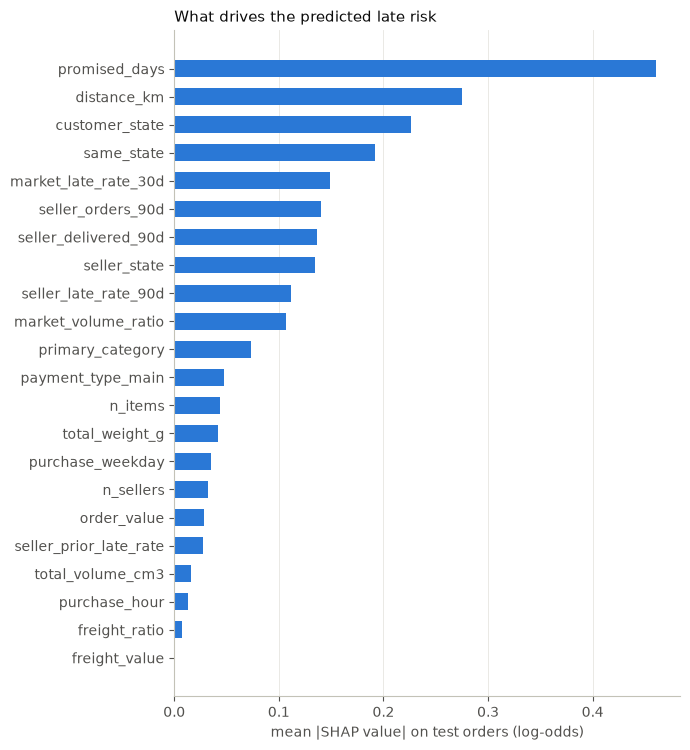

promised_days           0.460
distance_km             0.275
customer_state          0.227
same_state              0.192
market_late_rate_30d    0.149
seller_orders_90d       0.140
seller_delivered_90d    0.136
seller_state            0.134
seller_late_rate_90d    0.112
market_volume_ratio     0.106
dtype: float64

In [18]:
# Features constant in the test period only shift every test order by the same amount,
# so they can't separate risky from safe orders there; they're left off this chart.
constant_in_test = [f for f in FEATURES if x_te[f].nunique(dropna=False) <= 1]
print("constant in the test period (offset only):", constant_in_test)
importance = contrib_te.drop(columns=constant_in_test).abs().mean().sort_values()
fig, ax = plt.subplots(figsize=(7, 0.3 * len(importance) + 1))
ax.barh(importance.index, importance.values, color=BLUE, height=0.6)
ax.set_xlabel("mean |SHAP value| on test orders (log-odds)")
ax.grid(axis="y", visible=False)
ax.set_title("What drives the predicted late risk", loc="left", color=INK, fontsize=11)
plt.tight_layout()
fig.savefig(FIG_DIR / "model_shap_importance.png", dpi=150)
plt.show()
importance.sort_values(ascending=False).round(3).head(10)

In [19]:
# Direction of each main numeric effect = sign of the correlation between the feature value
# and its SHAP value, measured on TRAINING orders (where every feature varies)
contrib_tr = linear_contributions(model, x_tr)
top_numeric = [f for f in importance.sort_values(ascending=False).index if f in NUMERIC_FEATURES][
    :6
]
sign = {f: np.corrcoef(x_tr[f].fillna(x_tr[f].median()), contrib_tr[f])[0, 1] for f in top_numeric}
direction = pd.DataFrame(
    {
        "mean |SHAP| (test)": importance[top_numeric],
        "higher value ->": ["more risk" if sign[f] > 0 else "less risk" for f in top_numeric],
    }
)
direction.round(3)

,mean |SHAP| (test),higher value ->
promised_days,0.460,less risk
distance_km,0.275,more risk
same_state,0.192,less risk
market_late_rate_30d,0.149,less risk
seller_orders_90d,0.140,more risk
seller_delivered_90d,0.136,less risk


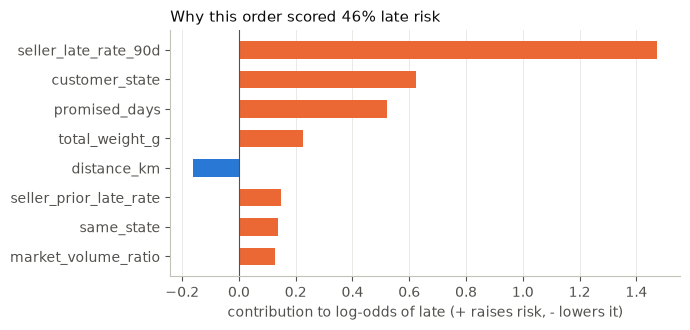

seller_late_rate_90d            1.0
customer_state                   RJ
promised_days                    16
total_weight_g              16500.0
distance_km               366.06814
seller_prior_late_rate          0.5
same_state                        0
market_volume_ratio        1.272384
Name: 92108, dtype: object

In [20]:
# One high-risk test order explained (the "waterfall" the app will show)
i = int(np.argmax(p_te_lr))
row = (
    contrib_te.drop(columns=constant_in_test)
    .iloc[i]
    .sort_values(key=np.abs, ascending=False)
    .head(8)[::-1]
)
fig, ax = plt.subplots(figsize=(7, 3.4))
ax.barh(row.index, row.values, color=[ORANGE if v > 0 else BLUE for v in row.values], height=0.6)
ax.axvline(0, color=INK2, linewidth=0.8)
ax.set_xlabel("contribution to log-odds of late (+ raises risk, - lowers it)")
ax.grid(axis="y", visible=False)
ax.set_title(
    f"Why this order scored {p_te_lr[i]:.0%} late risk", loc="left", color=INK, fontsize=11
)
plt.tight_layout()
fig.savefig(FIG_DIR / "model_example_explanation.png", dpi=150)
plt.show()
x_te.iloc[i][row.index[::-1]]

## 8. Save the model and write `fact_order_risk`

In [21]:
MODEL_VERSION = "logreg_v1_2026-10-19"
metadata = {
    "model_version": MODEL_VERSION,
    "model_type": "LogisticRegression (sklearn pipeline: impute + scale + one-hot)",
    "params": {
        k: v
        for k, v in model.named_steps["model"].get_params().items()
        if k in ("C", "class_weight")
    },
    "features": FEATURES,
    "numeric_features": NUMERIC_FEATURES,
    "categorical_features": CATEGORICAL_FEATURES,
    "train_period": [
        str(table.loc[table.split == "train", "purchase_ts"].min()),
        str(table.loc[table.split == "train", "purchase_ts"].max()),
    ],
    "valid_period": [
        str(table.loc[table.split == "valid", "purchase_ts"].min()),
        str(table.loc[table.split == "valid", "purchase_ts"].max()),
    ],
    "test_period": [
        str(table.loc[table.split == "test", "purchase_ts"].min()),
        str(table.loc[table.split == "test", "purchase_ts"].max()),
    ],
    "threshold": chosen["threshold"],
    "cost_fn": COST_FN,
    "cost_fp": COST_FP,
    "valid_metrics": valid_scores.loc["logistic regression", ["pr_auc", "roc_auc", "base_rate"]]
    .astype(float)
    .to_dict(),
    "test_metrics": test_scores.loc["logistic regression"].astype(float).to_dict(),
    "test_at_threshold": {k: float(v) for k, v in test_cm.items()},
    "lightgbm_comparison": {
        "valid_pr_auc": float(valid_scores.loc["LightGBM", "pr_auc"]),
        "test_pr_auc": float(test_scores.loc["LightGBM", "pr_auc"]),
    },
    "seed": 42,
}
model_path, meta_path = save_artifacts(model, metadata)
print(model_path.name, meta_path.name)

late_delivery_model.pkl metadata.json


In [22]:
p_all = model.predict_proba(table[FEATURES])[:, 1]
contrib_all = linear_contributions(model, table[FEATURES])
risk = pd.DataFrame(
    {
        "order_id": table["order_id"].to_numpy(),
        "split": table["split"].to_numpy(),
        "late_probability": p_all.round(4),
        "risk_band": risk_band(p_all, chosen["threshold"]),
        "model_version": MODEL_VERSION,
        "top_shap_features": top_drivers(contrib_all, k=3),
    }
)
risk_path = ROOT / "models" / "order_risk_scores.parquet"
risk.to_parquet(risk_path, index=False)
with connect(read_only=False) as con:
    con.execute(
        "CREATE OR REPLACE TABLE fact_order_risk AS SELECT * FROM read_parquet(?)", [str(risk_path)]
    )
    print(
        con.execute(
            "SELECT split, risk_band, COUNT(*) AS orders FROM fact_order_risk "
            "GROUP BY ALL ORDER BY split, risk_band"
        ).df()
    )
risk.head(3)

   split risk_band  orders
0   test      high    8772
1   test       low   10140
2   test    medium   13238
3  train      high   19049
4  train       low    8034
5  train    medium   16343
6  valid      high    4353
7  valid       low    6835
8  valid    medium    9439


,order_id,split,late_probability,risk_band,model_version,top_shap_features
0,ec7a019261fce44180373d45b442d78f,train,0.0021,low,logreg_v1_2026-10-19,market_volume_ratio (-0.87); market_late_rate_...
1,b95a0a8bd30aece4e94e81f0591249d8,train,0.0064,low,logreg_v1_2026-10-19,promised_days (-0.77); market_volume_ratio (+0...
2,38bcb524e1c38c2c1b60600a80fc8999,train,0.0090,low,logreg_v1_2026-10-19,market_volume_ratio (+1.21); promised_days (-0...


## 9. Limitations and next steps

- **Drift dominates.** The late rate swings from ~4% to ~13% between quarters; any fixed threshold needs re-setting. Monitor the base rate and recalibrate monthly.
- **Moderate signal.** Purchase-time data can't see carrier problems or weather; most of the risk is decided after purchase.
- **Linear limits.** In training, the platform late rate relates to lateness as an inverted U (quintile late rates 3.5% / 4.1% / 9.1% / 8.2% / 3.5%) and overlaps with the holiday flag (r = 0.30), so its linear weight is negative. Binning it, or a tree model once there's more stable history, could capture this.
- **Single split.** Results come from one train/valid/test split; a rolling backtest over several periods would show how stable they are.
- **Survivorship.** Orders still undelivered at the data cut-off (1-3% per month) have no label and are excluded.
- **Scores for train/valid orders are in-sample.** Use `split = 'test'` in `fact_order_risk` for honest dashboards.
- **Next:** the risk table feeds Power BI (Day 4) and the Streamlit risk page (Day 6).